In [4]:
#Importando bibliotecas

import os
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# Criando o DataFrame a partir do arquivo
arquivo = "data/RESULTADO_2025_30000.csv"

if not os.path.exists(arquivo):
    raise FileNotFoundError("Arquivo não encontrado. Abra o notebook na pasta principal do projeto.")

df = pd.read_csv(arquivo, sep=";", encoding="utf-16", decimal=",")
df.columns = df.columns.str.strip()

In [6]:
# Criando uma pasta para armazenar os gráficos
os.makedirs("graficos", exist_ok=True)

In [7]:
#Informações sobre o DF original

print("Linhas e colunas:", df.shape)
print("Quantidade de participantes:", len(df))
print("Total de colunas:", len(df.columns))
print("Registros repetidos no identificador:", df["NU_SEQUENCIAL"].duplicated().sum())
display(df.head(3))

Linhas e colunas: (29999, 70)
Quantidade de participantes: 29999
Total de colunas: 70
Registros repetidos no identificador: 0


,NU_SEQUENCIAL,NU_ANO,CO_ESCOLA,CO_MUNICIPIO_ESC,NO_MUNICIPIO_ESC,CO_UF_ESC,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,TP_SIT_FUNC_ESC,...,NU_NOTA_COMP3_AV3,NU_NOTA_COMP4_AV3,NU_NOTA_COMP5_AV3,TP_STATUS_REDACAO_AV4,NU_NOTA_AV4,NU_NOTA_COMP1_AV4,NU_NOTA_COMP2_AV4,NU_NOTA_COMP3_AV4,NU_NOTA_COMP4_AV4,NU_NOTA_COMP5_AV4
0,206403,2025,33083592,3304557,Rio de Janeiro,33,RJ,2,1,1,...,,,,,,,,,,
1,3604651,2025,21017115,2111300,São Luís,21,MA,2,1,1,...,,,,,,,,,,
2,1461268,2025,,,,,,,,,...,,,,,,,,,,


Notas preenchidas em cada prova:
NU_NOTA_CN         20365
NU_NOTA_CH         21633
NU_NOTA_LC         21633
NU_NOTA_MT         20365
NU_NOTA_REDACAO    21633
dtype: int64

Tipos de escola que aparecem no arquivo:
TP_DEPENDENCIA_ADM_ESC
1.0      459
2.0     8460
3.0       61
4.0     1714
NaN    19305
Name: count, dtype: int64

Localizações de escola que aparecem no arquivo:
TP_LOCALIZACAO_ESC
1.0    10157
2.0      537
NaN    19305
Name: count, dtype: int64
Registros com tipo de escola informado: 10694

Médias por tipo de escola:
                NU_NOTA_CN  NU_NOTA_CH  NU_NOTA_LC  NU_NOTA_MT  \
Tipo de escola                                                   
Federal              529.3       543.4       561.5       578.3   
Estadual             472.2       483.6       507.8       482.6   
Municipal            504.5       531.0       555.3       533.8   
Privada              552.1       566.7       578.9       617.3   

                NU_NOTA_REDACAO  
Tipo de escola                   
F

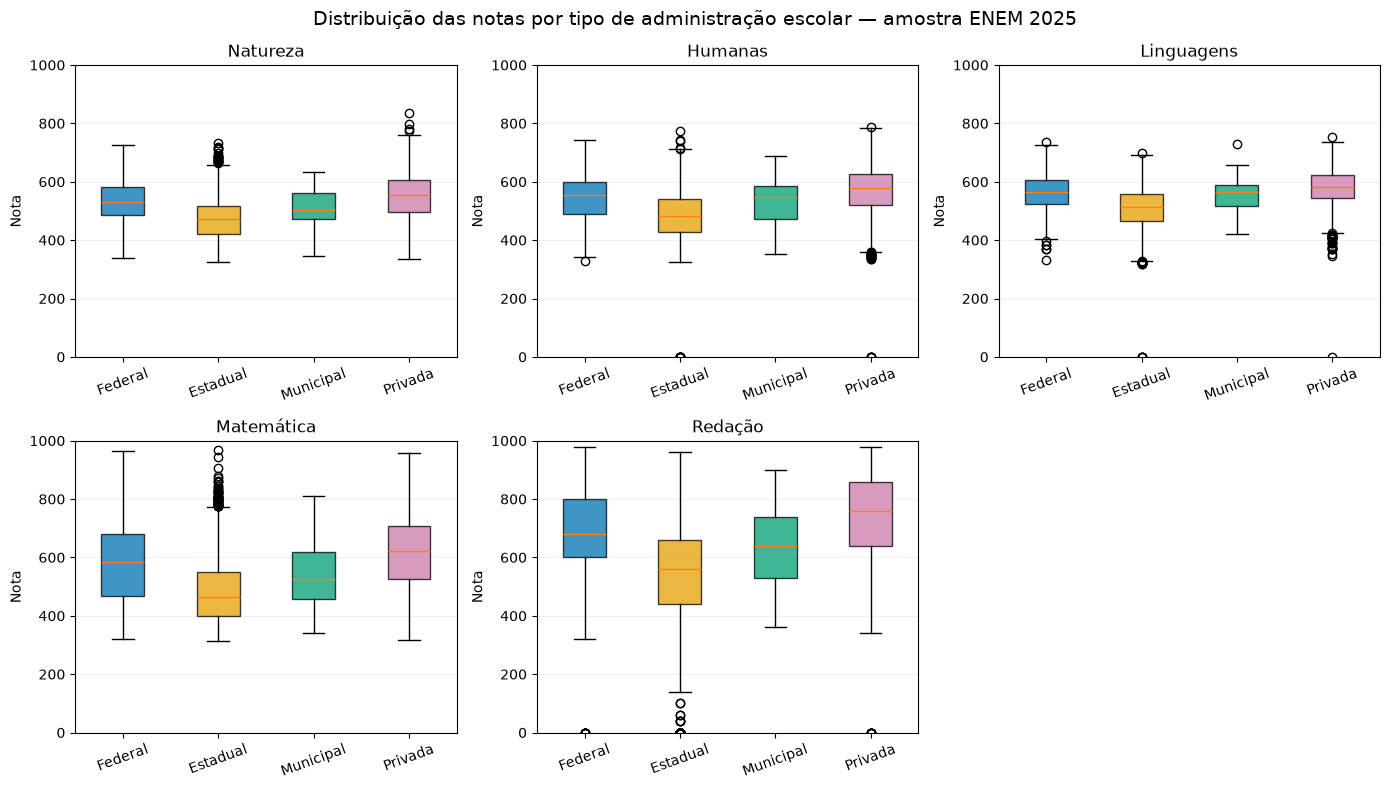

In [ ]:
# Colunas de nota que vamos analisar
notas = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]
competencias = ["NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3", "NU_NOTA_COMP4", "NU_NOTA_COMP5"]

# Transformando as notas em números
colunas_numericas = notas + competencias + ["NU_NOTA_AV1", "NU_NOTA_AV2", "NU_NOTA_AV3", "NU_NOTA_AV4"]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(
        df[coluna].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Transformando os códigos dos grupos em números
categorias = ["TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC", "TP_LINGUA",
              "TP_PRESENCA_CH", "TP_PRESENCA_MT"]

# Se o arquivo não tiver presença de CN ou LC, usamos a prova do mesmo dia
for coluna, referencia in [("TP_PRESENCA_CN", "TP_PRESENCA_MT"),
                           ("TP_PRESENCA_LC", "TP_PRESENCA_CH")]:
    if coluna not in df.columns:
        df[coluna] = df[referencia]
        print("Aviso:", coluna, "não existe. Usando a presença de", referencia)
    categorias.append(coluna)

for coluna in categorias:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Notas preenchidas em cada prova:")
print(df[notas].count())

print("\nTipos de escola que aparecem no arquivo:")
print(df["TP_DEPENDENCIA_ADM_ESC"].value_counts(dropna=False).sort_index())

print("\nLocalizações de escola que aparecem no arquivo:")
print(df["TP_LOCALIZACAO_ESC"].value_counts(dropna=False).sort_index())

# Desempenho por tipo de escola
tipos_escola = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
cores_escola = {
    "Federal": "#0072B2",
    "Estadual": "#E69F00",
    "Municipal": "#009E73",
    "Privada": "#CC79A7",
}
nomes_notas = ["Natureza", "Humanas", "Linguagens", "Matemática", "Redação"]

escolas = df.copy()
escolas["Tipo de escola"] = escolas["TP_DEPENDENCIA_ADM_ESC"].map(tipos_escola)

print("Registros com tipo de escola informado:", escolas["Tipo de escola"].notna().sum())
media_escolas = escolas.groupby("Tipo de escola")[notas].mean().reindex(tipos_escola.values())
qtd_escolas = escolas.groupby("Tipo de escola")[notas].count().reindex(tipos_escola.values())

print("\nMédias por tipo de escola:")
print(media_escolas.round(1).dropna(how="all"))
print("\nQuantidade de notas usadas por tipo de escola:")
print(qtd_escolas.dropna(how="all"))

if media_escolas.notna().any().any():
    fig, eixos = plt.subplots(2, 3, figsize=(14, 8))

    for i, nota in enumerate(notas):
        ax = eixos.flat[i]
        distribuicoes = []
        tipos_presentes = []

        for localizacao in tipos_escola.values():
            valores = escolas.loc[escolas["Tipo de escola"] == localizacao, nota].dropna()
            if not valores.empty:
                distribuicoes.append(valores)
                tipos_presentes.append(localizacao)

        if distribuicoes:
            caixas = ax.boxplot(
                distribuicoes,
                tick_labels=tipos_presentes,
                showfliers=True,
                patch_artist=True
            )
            for caixa, localizacao in zip(caixas["boxes"], tipos_presentes):
                caixa.set_facecolor(cores_escola[localizacao])
                caixa.set_alpha(0.75)
        else:
            ax.text(0.5, 0.5, "Sem notas disponíveis", ha="center", va="center", transform=ax.transAxes)

        ax.set_title(nomes_notas[i])
        ax.set_ylabel("Nota")
        ax.set_ylim(0, 1000)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.2)

    eixos.flat[5].axis("off")
    fig.suptitle("Distribuição das notas por tipo de administração escolar — amostra ENEM 2025", fontsize=14)
    plt.tight_layout()
    plt.savefig("graficos/01_notas_por_tipo_escola.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("\nNão foi possível comparar os tipos de escola.")
    print("O arquivo não tem registros com tipo de escola e nota preenchidos ao mesmo tempo.")
    print("Não vamos inventar uma comparação que a amostra não permite.")

Notas preenchidas em cada prova:
NU_NOTA_CN         20365
NU_NOTA_CH         21633
NU_NOTA_LC         21633
NU_NOTA_MT         20365
NU_NOTA_REDACAO    21633
dtype: int64

Tipos de escola que aparecem no arquivo:
TP_DEPENDENCIA_ADM_ESC
1.0      459
2.0     8460
3.0       61
4.0     1714
NaN    19305
Name: count, dtype: int64

Localizações de escola que aparecem no arquivo:
TP_LOCALIZACAO_ESC
1.0    10157
2.0      537
NaN    19305
Name: count, dtype: int64
Registros com localização de escola informado: 10694

Médias por localizacao de escola:
                       NU_NOTA_CN  NU_NOTA_CH  NU_NOTA_LC  NU_NOTA_MT  \
Localizacao de escola                                                   
Urbana                      492.5       504.6       526.4       517.2   
Rural                       469.5       471.9       489.3       468.6   

                       NU_NOTA_REDACAO  
Localizacao de escola                   
Urbana                           578.8  
Rural                            504

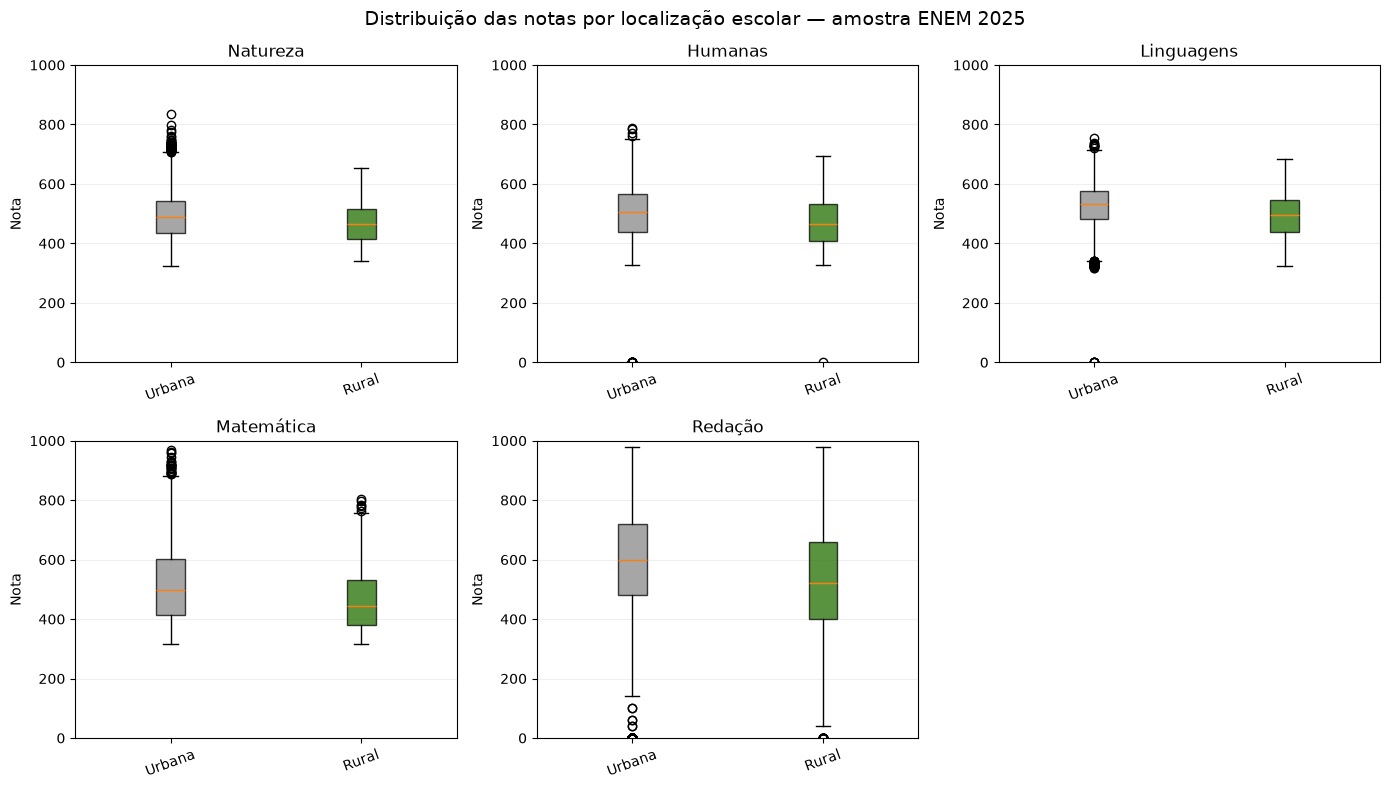

In [17]:
# Colunas de nota que vamos analisar
notas = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]
competencias = ["NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3", "NU_NOTA_COMP4", "NU_NOTA_COMP5"]

# Transformando as notas em números
colunas_numericas = notas + competencias + ["NU_NOTA_AV1", "NU_NOTA_AV2", "NU_NOTA_AV3", "NU_NOTA_AV4"]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(
        df[coluna].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Transformando os códigos dos grupos em números
categorias = ["TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC", "TP_LINGUA",
              "TP_PRESENCA_CH", "TP_PRESENCA_MT"]

# Se o arquivo não tiver presença de CN ou LC, usamos a prova do mesmo dia
for coluna, referencia in [("TP_PRESENCA_CN", "TP_PRESENCA_MT"),
                           ("TP_PRESENCA_LC", "TP_PRESENCA_CH")]:
    if coluna not in df.columns:
        df[coluna] = df[referencia]
        print("Aviso:", coluna, "não existe. Usando a presença de", referencia)
    categorias.append(coluna)

for coluna in categorias:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Notas preenchidas em cada prova:")
print(df[notas].count())

print("\nTipos de escola que aparecem no arquivo:")
print(df["TP_DEPENDENCIA_ADM_ESC"].value_counts(dropna=False).sort_index())

print("\nLocalizações de escola que aparecem no arquivo:")
print(df["TP_LOCALIZACAO_ESC"].value_counts(dropna=False).sort_index())

# Desempenho por localização de escola
localizacao_escola = {1: "Urbana", 2: "Rural"}
cores_escola = {
    "Urbana": "#888888",
    "Rural": "#236F00FF",
}
nomes_notas = ["Natureza", "Humanas", "Linguagens", "Matemática", "Redação"]

escolas = df.copy()
escolas["Localizacao de escola"] = escolas["TP_LOCALIZACAO_ESC"].map(localizacao_escola)

print("Registros com localização de escola informado:", escolas["Localizacao de escola"].notna().sum())
media_escolas = escolas.groupby("Localizacao de escola")[notas].mean().reindex(localizacao_escola.values())
qtd_escolas = escolas.groupby("Localizacao de escola")[notas].count().reindex(localizacao_escola.values())

print("\nMédias por localizacao de escola:")
print(media_escolas.round(1).dropna(how="all"))
print("\nQuantidade de notas usadas por localizacao de escola:")
print(qtd_escolas.dropna(how="all"))

if media_escolas.notna().any().any():
    fig, eixos = plt.subplots(2, 3, figsize=(14, 8))

    for i, nota in enumerate(notas):
        ax = eixos.flat[i]
        distribuicoes = []
        tipos_presentes = []

        for localizacao in localizacao_escola.values():
            valores = escolas.loc[escolas["Localizacao de escola"] == localizacao, nota].dropna()
            if not valores.empty:
                distribuicoes.append(valores)
                tipos_presentes.append(localizacao)

        if distribuicoes:
            caixas = ax.boxplot(
                distribuicoes,
                tick_labels=tipos_presentes,
                showfliers=True,
                patch_artist=True
            )
            for caixa, localizacao in zip(caixas["boxes"], tipos_presentes):
                caixa.set_facecolor(cores_escola[localizacao])
                caixa.set_alpha(0.75)
        else:
            ax.text(0.5, 0.5, "Sem notas disponíveis", ha="center", va="center", transform=ax.transAxes)

        ax.set_title(nomes_notas[i])
        ax.set_ylabel("Nota")
        ax.set_ylim(0, 1000)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.2)

    eixos.flat[5].axis("off")
    fig.suptitle("Distribuição das notas por localização escolar — amostra ENEM 2025", fontsize=14)
    plt.tight_layout()
    plt.savefig("graficos/01_notas_por_tipo_escola.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("\nNão foi possível comparar os tipos de escola.")
    print("O arquivo não tem registros com localizacao de escola e nota preenchidos ao mesmo tempo.")
    print("Não vamos inventar uma comparação que a amostra não permite.")

Registros com redação e localização de escola: 8337
             Quantidade  Acima de 800 (%)
Localização                              
Rural               379              6.33
Urbana             7958             13.92


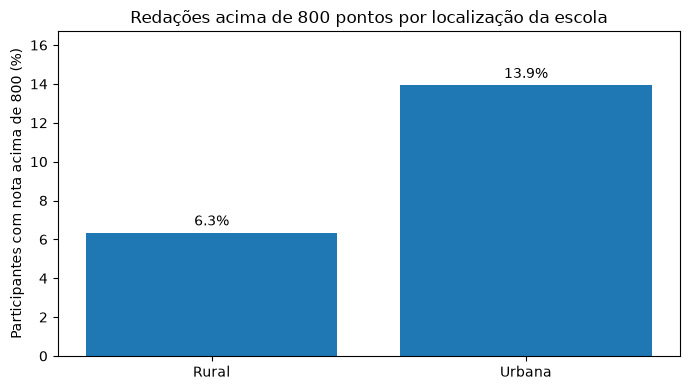

In [18]:
#Escola urbana ou rural e redações acima de 800

localizacao = {1: "Urbana", 2: "Rural"}

redacoes_local = df[df["NU_NOTA_REDACAO"].notna()].copy()
redacoes_local["Localização"] = redacoes_local["TP_LOCALIZACAO_ESC"].map(localizacao)
redacoes_local = redacoes_local.dropna(subset=["Localização"])
redacoes_local["Acima de 800"] = redacoes_local["NU_NOTA_REDACAO"] > 800

percentual_800 = redacoes_local.groupby("Localização")["Acima de 800"].mean() * 100
quantidade_local = redacoes_local["Localização"].value_counts()

print("Registros com redação e localização de escola:", len(redacoes_local))
print(pd.DataFrame({"Quantidade": quantidade_local,
                    "Acima de 800 (%)": percentual_800}).round(2))

if not percentual_800.empty:
    plt.figure(figsize=(7, 4))
    barras = plt.bar(percentual_800.index, percentual_800.values)
    plt.bar_label(barras, fmt="%.1f%%", padding=3)
    plt.title("Redações acima de 800 pontos por localização da escola")
    plt.ylabel("Participantes com nota acima de 800 (%)")
    plt.ylim(0, max(percentual_800.max() * 1.2, 1))
    plt.tight_layout()
    plt.savefig("graficos/02_urbana_rural.png", dpi=160)
    plt.show()
else:
    print("Não há registros suficientes de escola urbana/rural na amostra.")
    print("Por isso, não será mostrado um gráfico vazio.")